# Exploratory Data Analysis: Abalone Dataset

## Objective
Perform a thorough initial analysis of the Abalone dataset to understand the structure, distribution, and relationships among its features. This notebook supports two future predictive tasks:

1. **Task 1 — Sex Classification:** Predict the biological sex (M, F, I) using all physical measurements **plus** the number of rings.
2. **Task 2 — Age Regression:** Predict the number of rings (proxy for age) using all physical measurements **plus** the sex label.

The analysis is organized as follows:
- Data loading, integrity checks, and descriptive statistics
- Distribution analysis with respect to **Sex** (target of Task 1)
- Scatter plots of every feature pair colored by Sex to identify separability
- Correlation and feature importance for both target variables
- Distribution analysis with respect to **Rings / Age** (target of Task 2)
- Unsupervised clustering comparison to assess natural data groupings
- Expanded conclusions and implications for modeling

## Data Dictionary
| Feature | Description | Type |
|---------|-------------|------|
| **Sex** | Biological sex: Male (M), Female (F), Infant (I) | Categorical |
| **Length** | Longest shell measurement (mm) | Continuous |
| **Diameter** | Perpendicular to length (mm) | Continuous |
| **Height** | With meat in shell (mm) | Continuous |
| **Whole weight** | Weight of entire abalone (g) | Continuous |
| **Shucked weight** | Weight of meat (g) | Continuous |
| **Viscera weight** | Gut weight after bleeding (g) | Continuous |
| **Shell weight** | Weight after drying (g) | Continuous |
| **Rings** | Number of rings; age ≈ rings + 1.5 (years) | Integer |

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans, AgglomerativeClustering, DBSCAN,
    MeanShift, SpectralClustering, Birch
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 12

# Color palette used throughout the notebook
SEX_COLORS = {'M': '#3498db', 'F': '#e74c3c', 'I': '#2ecc71'}

%matplotlib inline

---
## 1. Data Loading & Integrity Checks

We start by loading the dataset and verifying its basic properties: shape, data types, missing values, and duplicates.

In [2]:
df = pd.read_csv('train/abalone_dataset.csv')

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"\nColumn names: {list(df.columns)}")
print(f"\nData types:")
print(df.dtypes)
print(f"\nMissing values per column:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print(f"\nHeight = 0 (suspicious): {(df['height'] == 0).sum()} rows")
df.head(10)

Dataset shape: 4177 rows × 9 columns

Column names: ['sex', 'length', 'diameter', 'height', 'whole_weight', 'shucked_weight', 'viscera_weight', 'shell_weight', 'number_of_rings']

Data types:
sex                 object
length             float64
diameter           float64
height             float64
whole_weight       float64
shucked_weight     float64
viscera_weight     float64
shell_weight       float64
number_of_rings      int64
dtype: object

Missing values per column:
sex                0
length             0
diameter           0
height             0
whole_weight       0
shucked_weight     0
viscera_weight     0
shell_weight       0
number_of_rings    0
dtype: int64

Duplicate rows: 0

Height = 0 (suspicious): 2 rows


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,number_of_rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7
5,I,0.425,0.300,0.095,0.3515,0.1410,0.0775,0.120,8
6,F,0.530,0.415,0.150,0.7775,0.2370,0.1415,0.330,20
7,F,0.545,0.425,0.125,0.7680,0.2940,0.1495,0.260,16
8,M,0.475,0.370,0.125,0.5095,0.2165,0.1125,0.165,9
9,F,0.550,0.440,0.150,0.8945,0.3145,0.1510,0.320,19


In [3]:
print("=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)
df.describe(include='all').round(4)

DESCRIPTIVE STATISTICS


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,number_of_rings
count,4177,4177.0000,4177.0000,4177.0000,4177.0000,4177.0000,4177.0000,4177.0000,4177.0000
unique,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1528,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,0.5240,0.4079,0.1395,0.8287,0.3594,0.1806,0.2388,9.9337
std,NaN,0.1201,0.0992,0.0418,0.4904,0.2220,0.1096,0.1392,3.2242
min,NaN,0.0750,0.0550,0.0000,0.0020,0.0010,0.0005,0.0015,1.0000
25%,NaN,0.4500,0.3500,0.1150,0.4415,0.1860,0.0935,0.1300,8.0000
50%,NaN,0.5450,0.4250,0.1400,0.7995,0.3360,0.1710,0.2340,9.0000
75%,NaN,0.6150,0.4800,0.1650,1.1530,0.5020,0.2530,0.3290,11.0000


In [4]:
print("Sex label distribution (Task 1 target):")
print(df['sex'].value_counts())
print(f"\nProportions:")
print(df['sex'].value_counts(normalize=True).round(3))

print(f"\nNumber of Rings distribution (Task 2 target):")
print(f"  Min: {df['number_of_rings'].min()}, Max: {df['number_of_rings'].max()}, "
      f"Mean: {df['number_of_rings'].mean():.2f}, Median: {df['number_of_rings'].median():.1f}, "
      f"Std: {df['number_of_rings'].std():.2f}")
print(f"  Unique values: {df['number_of_rings'].nunique()}")

Sex label distribution (Task 1 target):
sex
M    1528
I    1342
F    1307
Name: count, dtype: int64

Proportions:
sex
M    0.366
I    0.321
F    0.313
Name: proportion, dtype: float64

Number of Rings distribution (Task 2 target):
  Min: 1, Max: 29, Mean: 9.93, Median: 9.0, Std: 3.22
  Unique values: 28


### 1.1 Initial Data Quality Observations

Key points to note at this stage:
- The dataset has **no missing values**, which simplifies preprocessing.
- `height` contains a minimum of **0.0**, which is physically impossible — these are likely measurement errors or missing values encoded as zero.
- The `sex` variable has **3 classes** (M, F, I) with a reasonably balanced distribution (~36% M, ~32% I, ~31% F).
- `number_of_rings` ranges from 1 to 29, with a right-skewed distribution (mean ≈ 9.9, median = 9).

---
## 2. Distribution Analysis by Sex (Task 1 Target)

Understanding how each feature distributes across the three sex categories is essential for **Task 1** (Sex classification). If features show clear separation between M, F, and I, the classification problem will be easier.

### 2.1 Histograms — Feature distributions colored by Sex

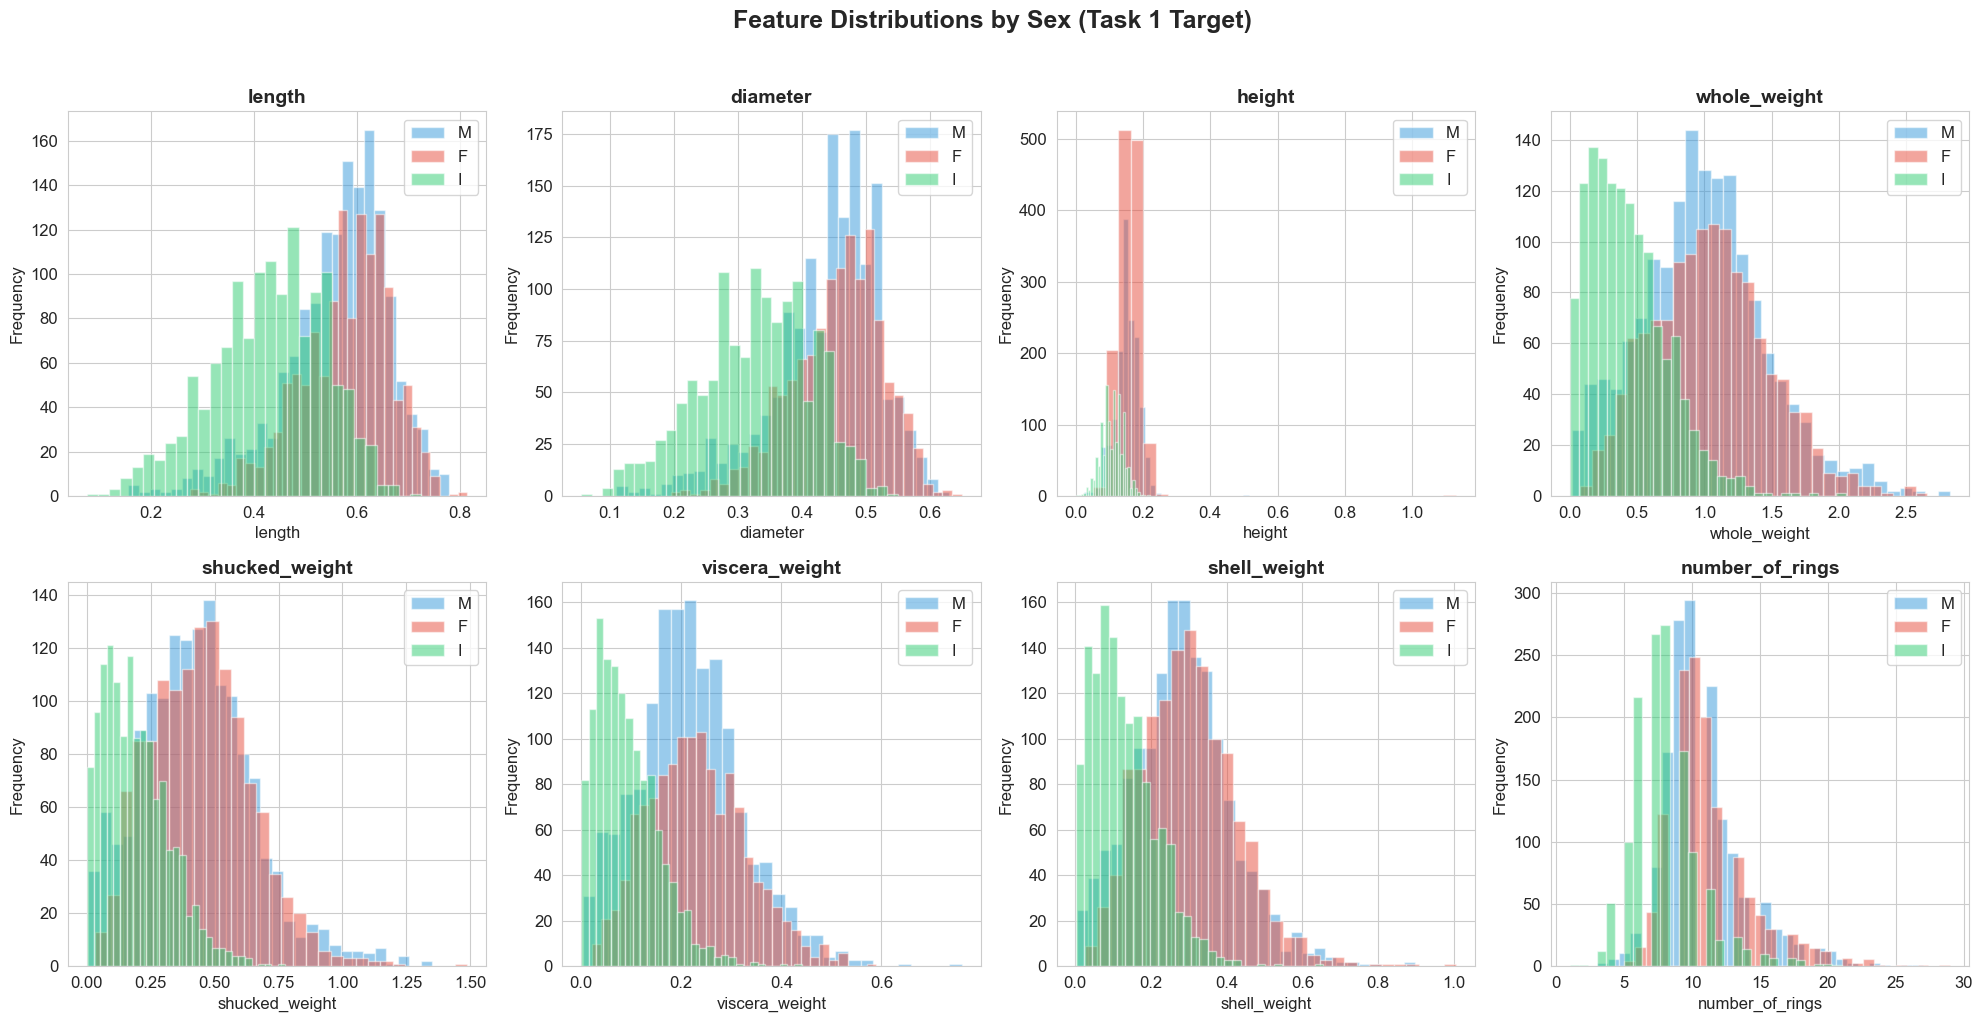

In [5]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    for sex in ['M', 'F', 'I']:
        subset = df[df['sex'] == sex][col]
        axes[i].hist(subset, bins=30, alpha=0.5, label=sex, color=SEX_COLORS[sex], edgecolor='white')
    axes[i].set_title(col, fontsize=14, fontweight='bold')
    axes[i].legend()
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

plt.suptitle('Feature Distributions by Sex (Task 1 Target)', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 2.2 Boxplots — Feature spread by Sex

Boxplots help visualize the median, quartiles, and outliers for each feature grouped by sex. They are especially useful to spot whether **Infants** are statistically different from **Males** and **Females**.

/tmp/ipykernel_113485/3495590563.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sex', y=col, data=df, ax=axes[i], palette=SEX_COLORS, order=['M', 'F', 'I'])
/tmp/ipykernel_113485/3495590563.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sex', y=col, data=df, ax=axes[i], palette=SEX_COLORS, order=['M', 'F', 'I'])
/tmp/ipykernel_113485/3495590563.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sex', y=col, data=df, ax=axes[i], palette=SEX_COLORS, order=['M', 'F', 'I'])
/tmp/ipykernel_113485/3495590563.py:5: FutureWarning

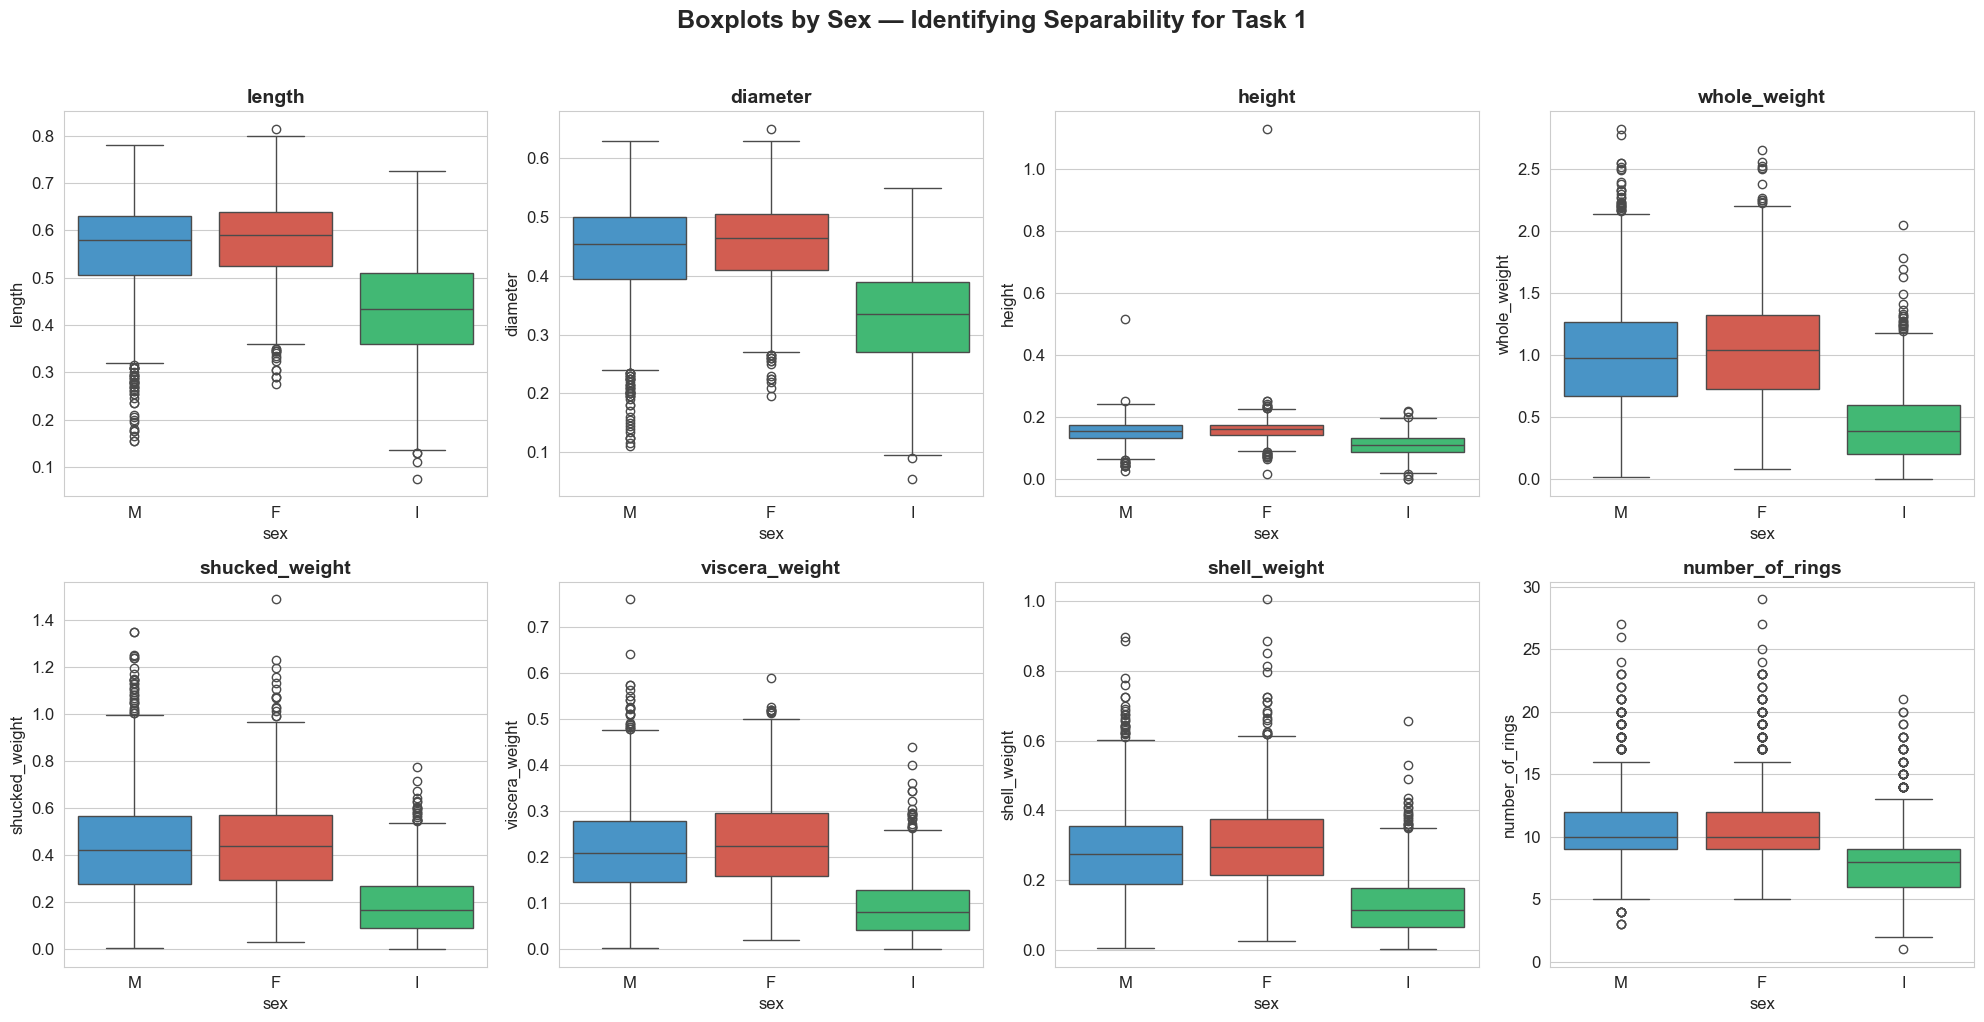

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(x='sex', y=col, data=df, ax=axes[i], palette=SEX_COLORS, order=['M', 'F', 'I'])
    axes[i].set_title(col, fontsize=14, fontweight='bold')

plt.suptitle('Boxplots by Sex — Identifying Separability for Task 1', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 3. Scatter Plots — Feature Pair Separability by Sex

For **Task 1**, it is crucial to identify which feature pairs offer the best visual separation between the three sex categories. Each scatter plot below shows one pair of numeric features, with points colored by sex.

**What to look for:**
- Clusters of the same color that are spatially separated → good feature pair for classification.
- Heavy overlap between M and F → these classes will be hard to separate.
- Clear separation of I (Infants) → Infant detection should be the easier sub-task.

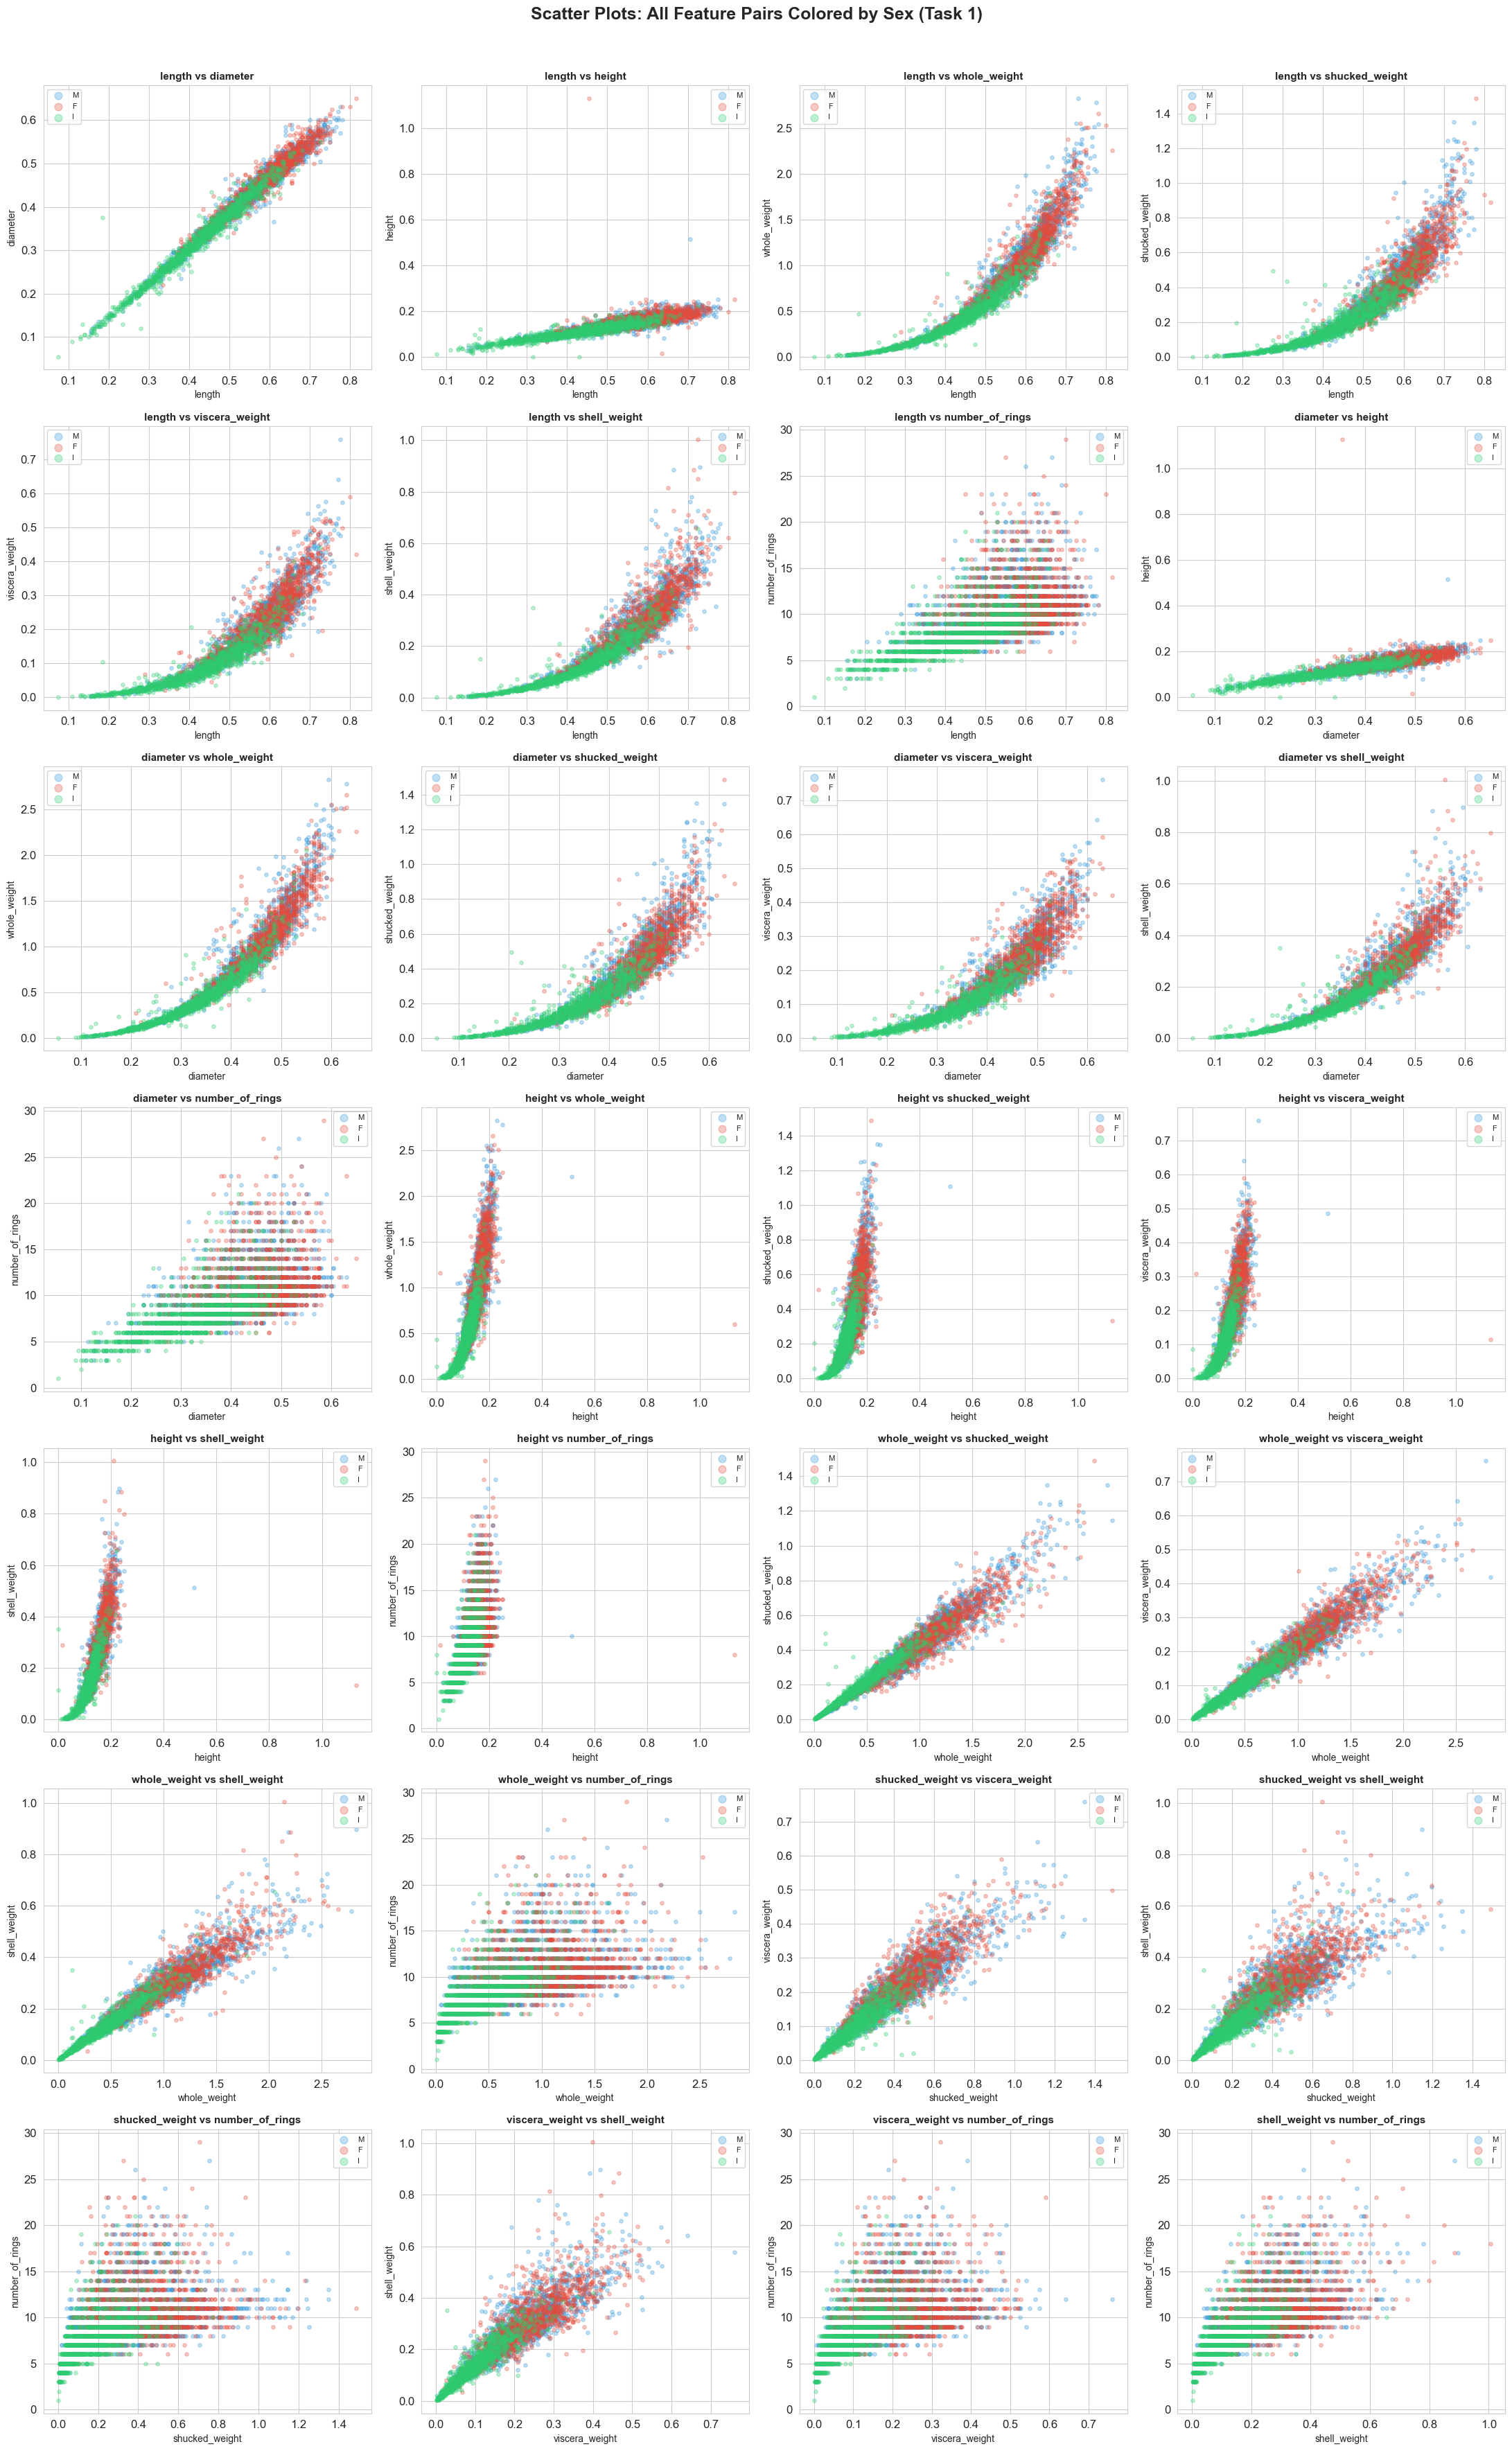

In [7]:
pairs = list(combinations(numeric_cols, 2))
n_pairs = len(pairs)
n_cols_plot = 4
n_rows_plot = (n_pairs + n_cols_plot - 1) // n_cols_plot

fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(22, 5 * n_rows_plot))
axes = axes.flatten()

for idx, (col_x, col_y) in enumerate(pairs):
    for sex in ['M', 'F', 'I']:
        mask = df['sex'] == sex
        axes[idx].scatter(df.loc[mask, col_x], df.loc[mask, col_y],
                          alpha=0.3, s=15, label=sex, color=SEX_COLORS[sex])
    axes[idx].set_xlabel(col_x, fontsize=10)
    axes[idx].set_ylabel(col_y, fontsize=10)
    axes[idx].set_title(f'{col_x} vs {col_y}', fontsize=11, fontweight='bold')
    axes[idx].legend(fontsize=8, markerscale=2)

# Hide unused axes
for j in range(idx + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Scatter Plots: All Feature Pairs Colored by Sex (Task 1)',
             fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 3.1 Pairplot — Quick Summary View

A seaborn pairplot provides a compact overview of all pairwise relationships with density estimates on the diagonal. A random sample of 1500 points is used for readability.

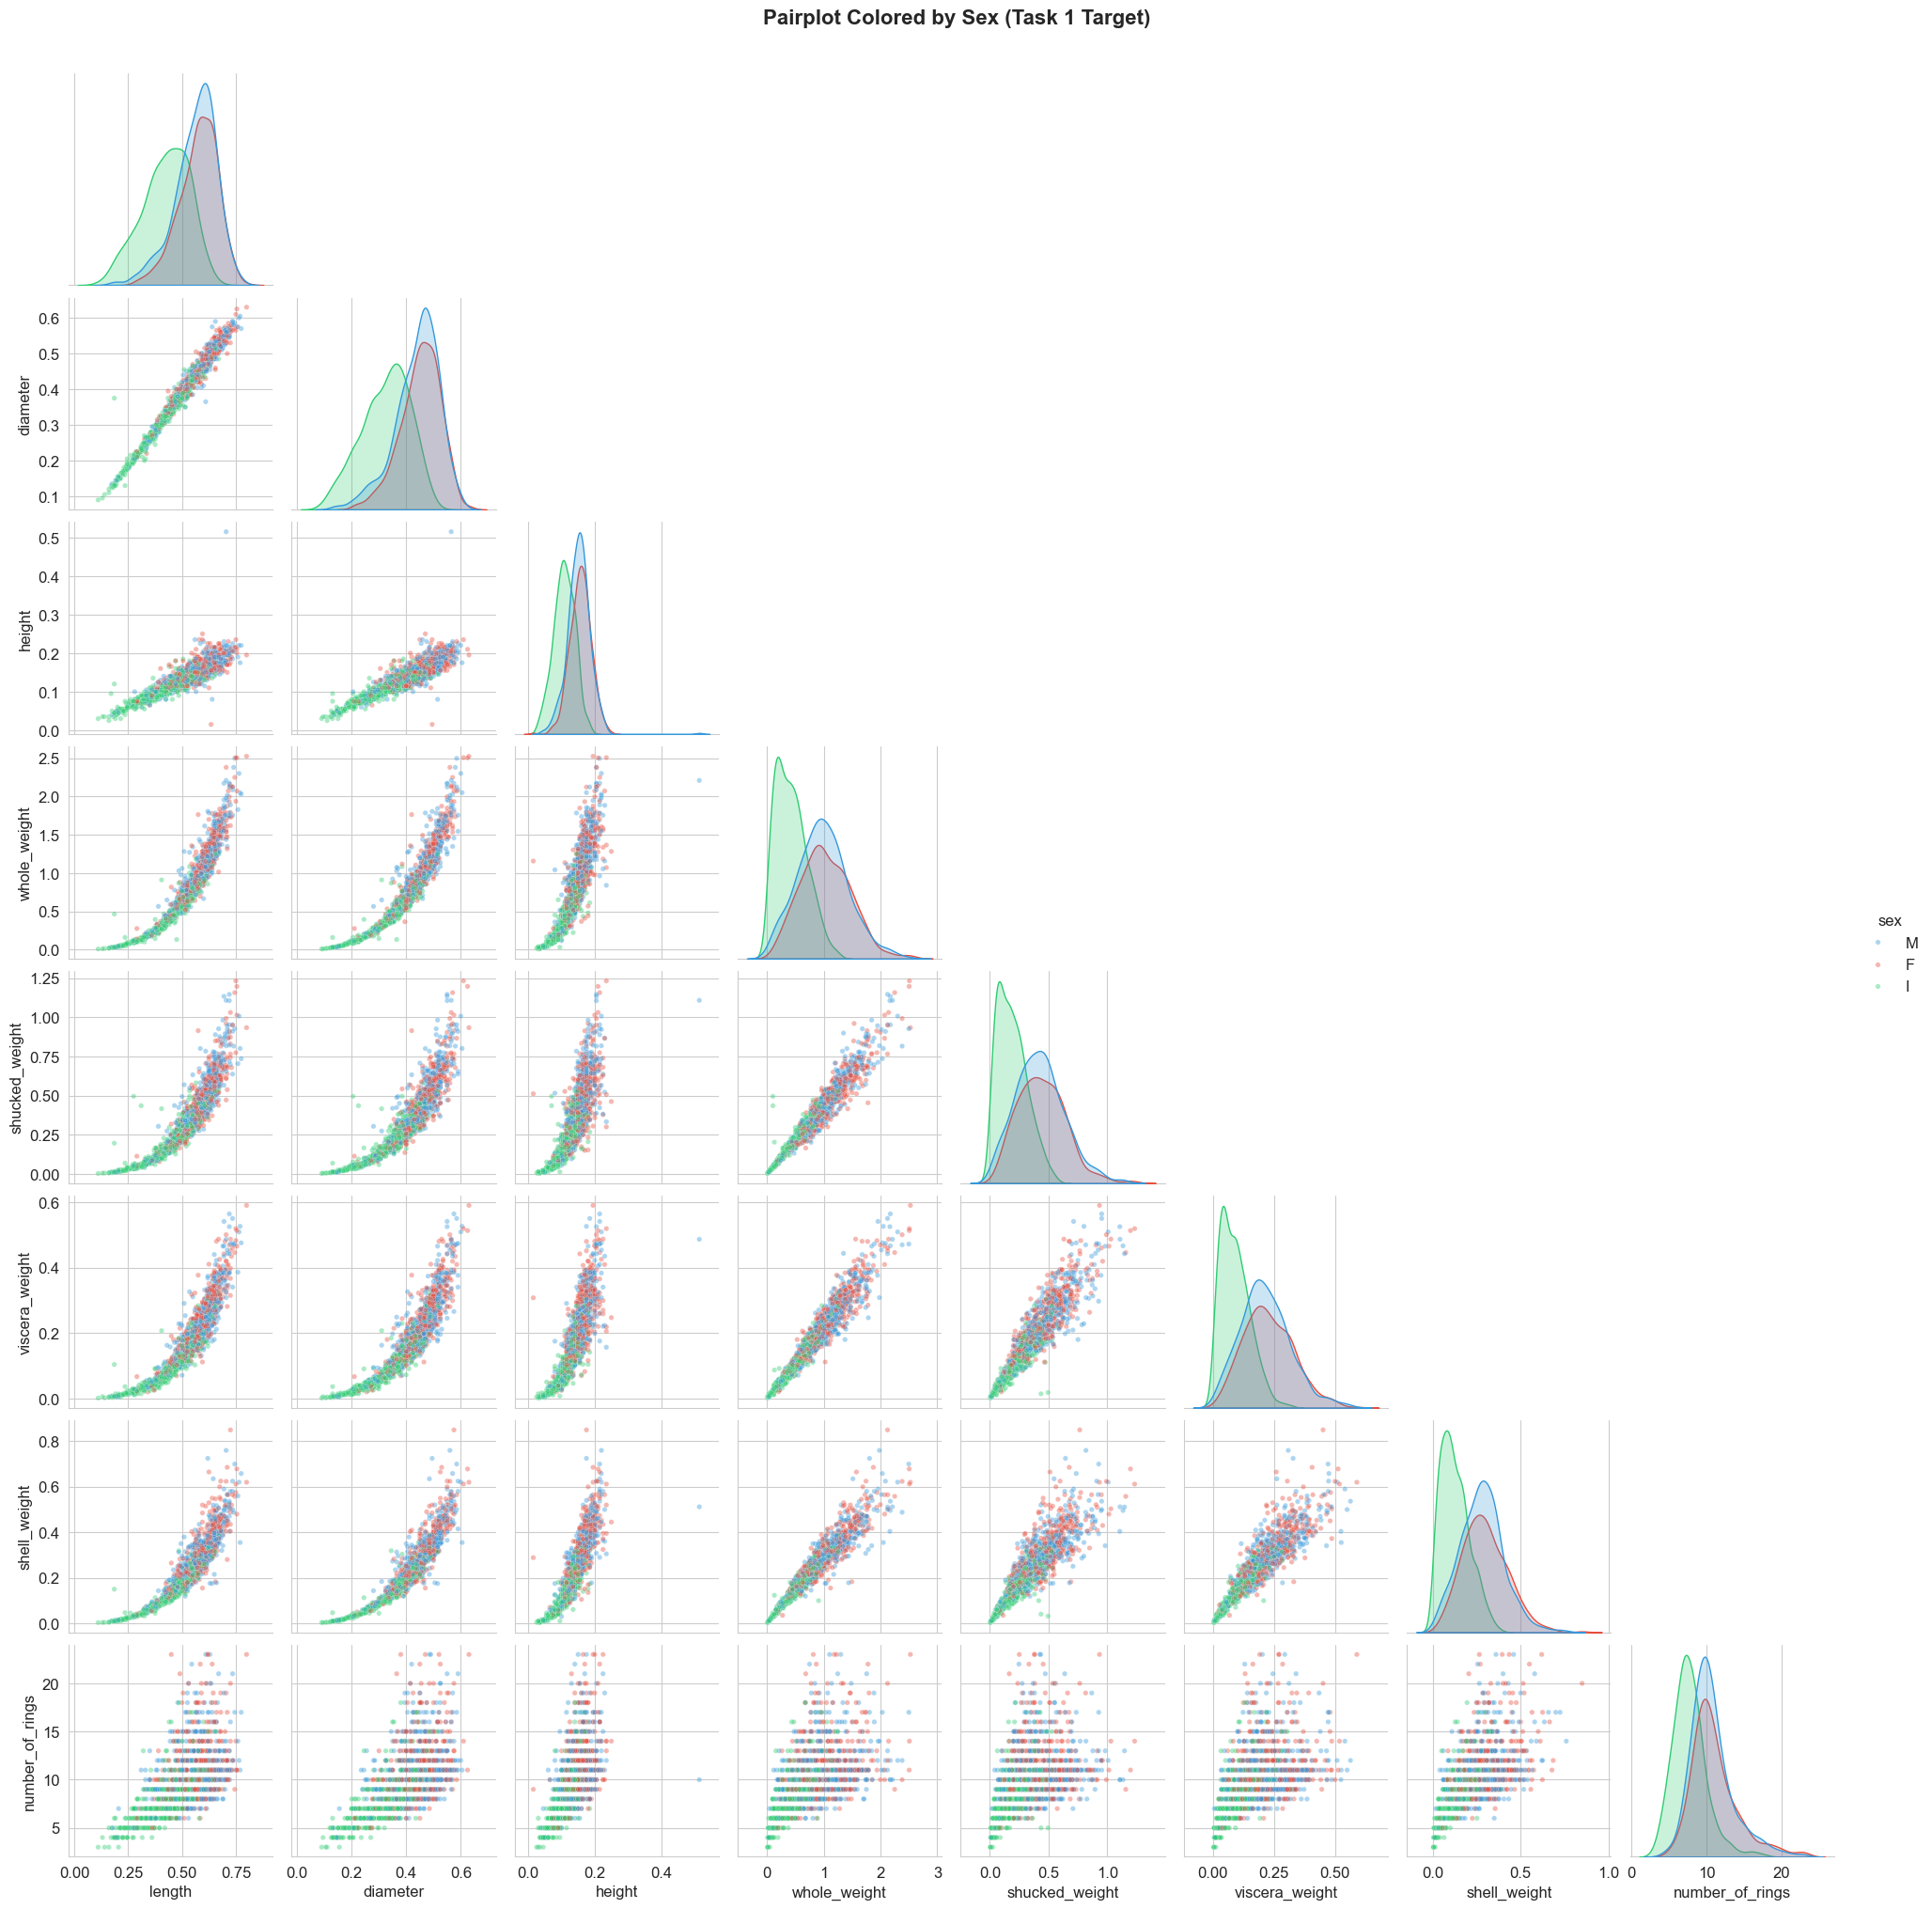

In [8]:
sample = df.sample(n=min(1500, len(df)), random_state=42)
g = sns.pairplot(sample, hue='sex', palette=SEX_COLORS, plot_kws={'alpha': 0.4, 's': 15},
                 diag_kind='kde', corner=True)
g.figure.suptitle('Pairplot Colored by Sex (Task 1 Target)', y=1.02, fontsize=16, fontweight='bold')
plt.show()

---
## 4. Correlation & Feature Importance

This section quantifies the linear relationships between all features, including the two target variables:
- **`sex_encoded`** — numerically encoded sex (for Task 1 analysis)
- **`number_of_rings`** — the age proxy (Task 2 target)

### 4.1 Full Correlation Matrix

Sex encoding: {'F': 0, 'I': 1, 'M': 2}


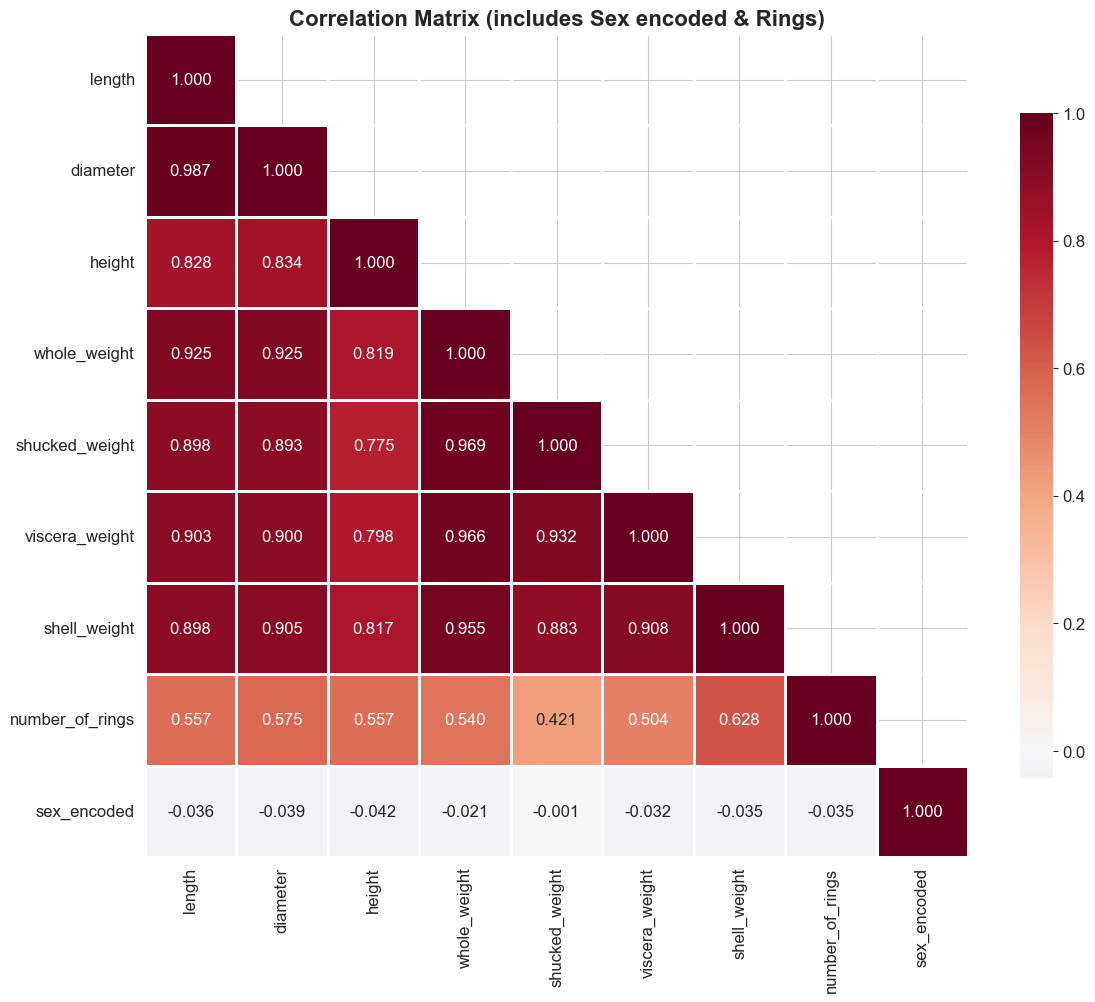

In [9]:
# Encode Sex numerically for correlation analysis
df_encoded = df.copy()
le = LabelEncoder()
df_encoded['sex_encoded'] = le.fit_transform(df_encoded['sex'])
print(f"Sex encoding: {dict(zip(le.classes_, le.transform(le.classes_)))}")

corr_cols = numeric_cols + ['sex_encoded']
corr = df_encoded[corr_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            mask=mask, square=True, linewidths=1, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Matrix (includes Sex encoded & Rings)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.2 Feature Correlation with Both Targets

Side-by-side comparison showing which features are most linearly correlated with:
- **Sex** (left) — relevant for Task 1
- **Number of Rings** (right) — relevant for Task 2

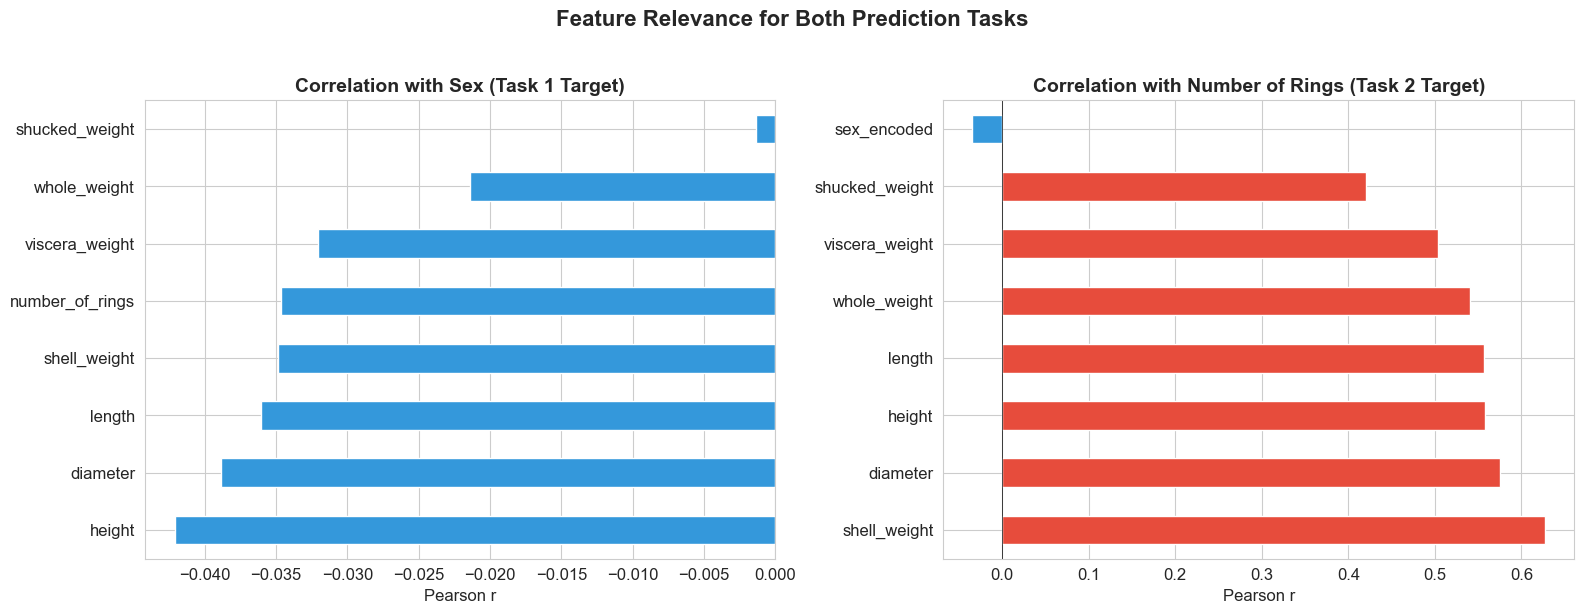


=== Feature correlations with Sex (Task 1) ===
height            -0.0421
diameter          -0.0389
length            -0.0361
shell_weight      -0.0349
number_of_rings   -0.0346
viscera_weight    -0.0321
whole_weight      -0.0214
shucked_weight    -0.0014

=== Feature correlations with Rings (Task 2) ===
shell_weight      0.6276
diameter          0.5747
height            0.5575
length            0.5567
whole_weight      0.5404
viscera_weight    0.5038
shucked_weight    0.4209
sex_encoded      -0.0346


In [10]:
corr_sex = df_encoded[corr_cols].corr()['sex_encoded'].drop('sex_encoded').sort_values(key=abs, ascending=False)
corr_rings = df_encoded[corr_cols].corr()['number_of_rings'].drop('number_of_rings').sort_values(key=abs, ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Task 1: correlation with Sex
corr_sex.plot(kind='barh', ax=ax1, color=['#e74c3c' if v > 0 else '#3498db' for v in corr_sex])
ax1.set_title('Correlation with Sex (Task 1 Target)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Pearson r')
ax1.axvline(x=0, color='black', linewidth=0.5)

# Task 2: correlation with Rings
corr_rings.plot(kind='barh', ax=ax2, color=['#e74c3c' if v > 0 else '#3498db' for v in corr_rings])
ax2.set_title('Correlation with Number of Rings (Task 2 Target)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Pearson r')
ax2.axvline(x=0, color='black', linewidth=0.5)

plt.suptitle('Feature Relevance for Both Prediction Tasks', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n=== Feature correlations with Sex (Task 1) ===")
print(corr_sex.round(4).to_string())
print("\n=== Feature correlations with Rings (Task 2) ===")
print(corr_rings.round(4).to_string())

---
## 5. Distribution Analysis by Age / Rings (Task 2 Target)

For **Task 2**, we need to understand how the physical features change as the abalone ages (more rings). This section explores the relationship between age and the continuous features.

### 5.1 Rings Distribution — Overall and by Sex

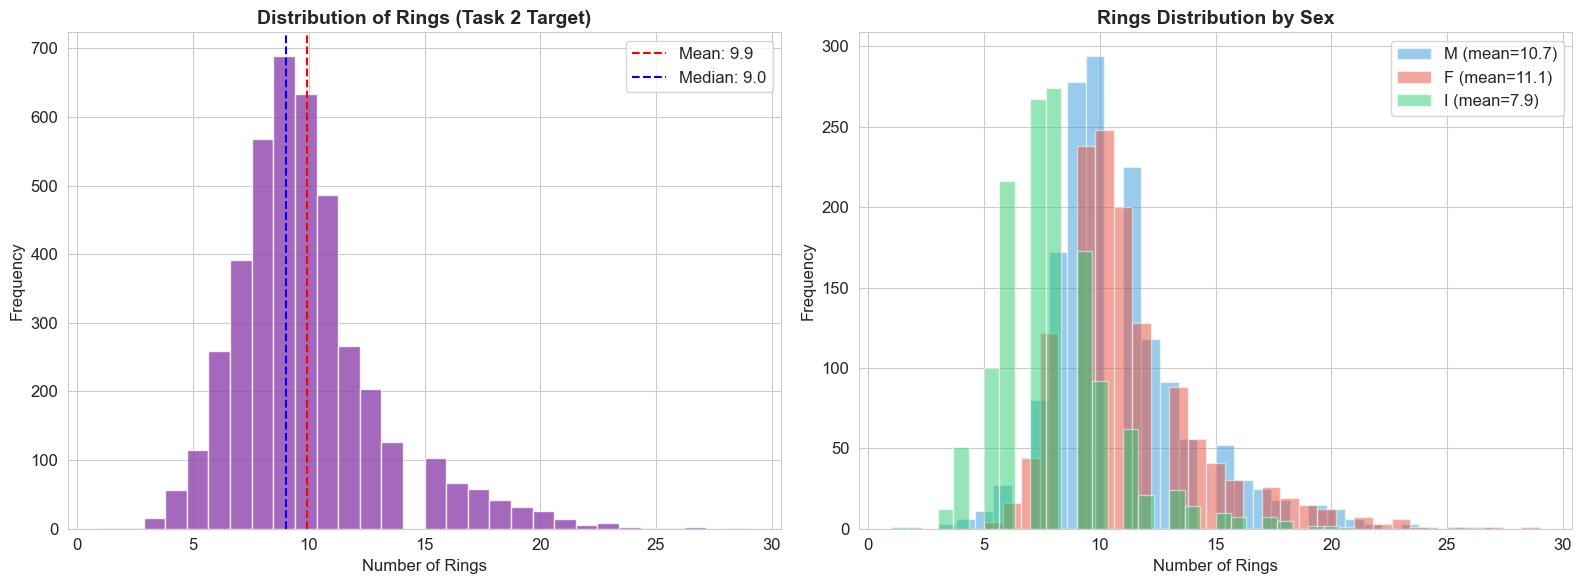

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Overall distribution
df['number_of_rings'].hist(bins=30, ax=ax1, color='#8e44ad', edgecolor='white', alpha=0.8)
ax1.set_title('Distribution of Rings (Task 2 Target)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Number of Rings')
ax1.set_ylabel('Frequency')
ax1.axvline(df['number_of_rings'].mean(), color='red', linestyle='--',
            label=f"Mean: {df['number_of_rings'].mean():.1f}")
ax1.axvline(df['number_of_rings'].median(), color='blue', linestyle='--',
            label=f"Median: {df['number_of_rings'].median():.1f}")
ax1.legend()

# Distribution by sex
for sex in ['M', 'F', 'I']:
    subset = df[df['sex'] == sex]['number_of_rings']
    ax2.hist(subset, bins=30, alpha=0.5,
             label=f"{sex} (mean={subset.mean():.1f})",
             color=SEX_COLORS[sex], edgecolor='white')
ax2.set_title('Rings Distribution by Sex', fontsize=14, fontweight='bold')
ax2.set_xlabel('Number of Rings')
ax2.set_ylabel('Frequency')
ax2.legend()

plt.tight_layout()
plt.show()

### 5.2 Violin Plots — Feature distributions grouped by Age Range

To understand whether features change meaningfully across different life stages, we bin the rings into four age groups and visualize with violin plots.

Age group distribution:
age_group
Young (1-7)            839
Young Adult (8-10)    1891
Adult (11-15)         1186
Old (16+)              261
Name: count, dtype: int64


/tmp/ipykernel_113485/3815182538.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='age_group', y=col, data=df, ax=axes[i],
/tmp/ipykernel_113485/3815182538.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='age_group', y=col, data=df, ax=axes[i],
/tmp/ipykernel_113485/3815182538.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='age_group', y=col, data=df, ax=axes[i],
/tmp/ipykernel_113485/3815182538.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign

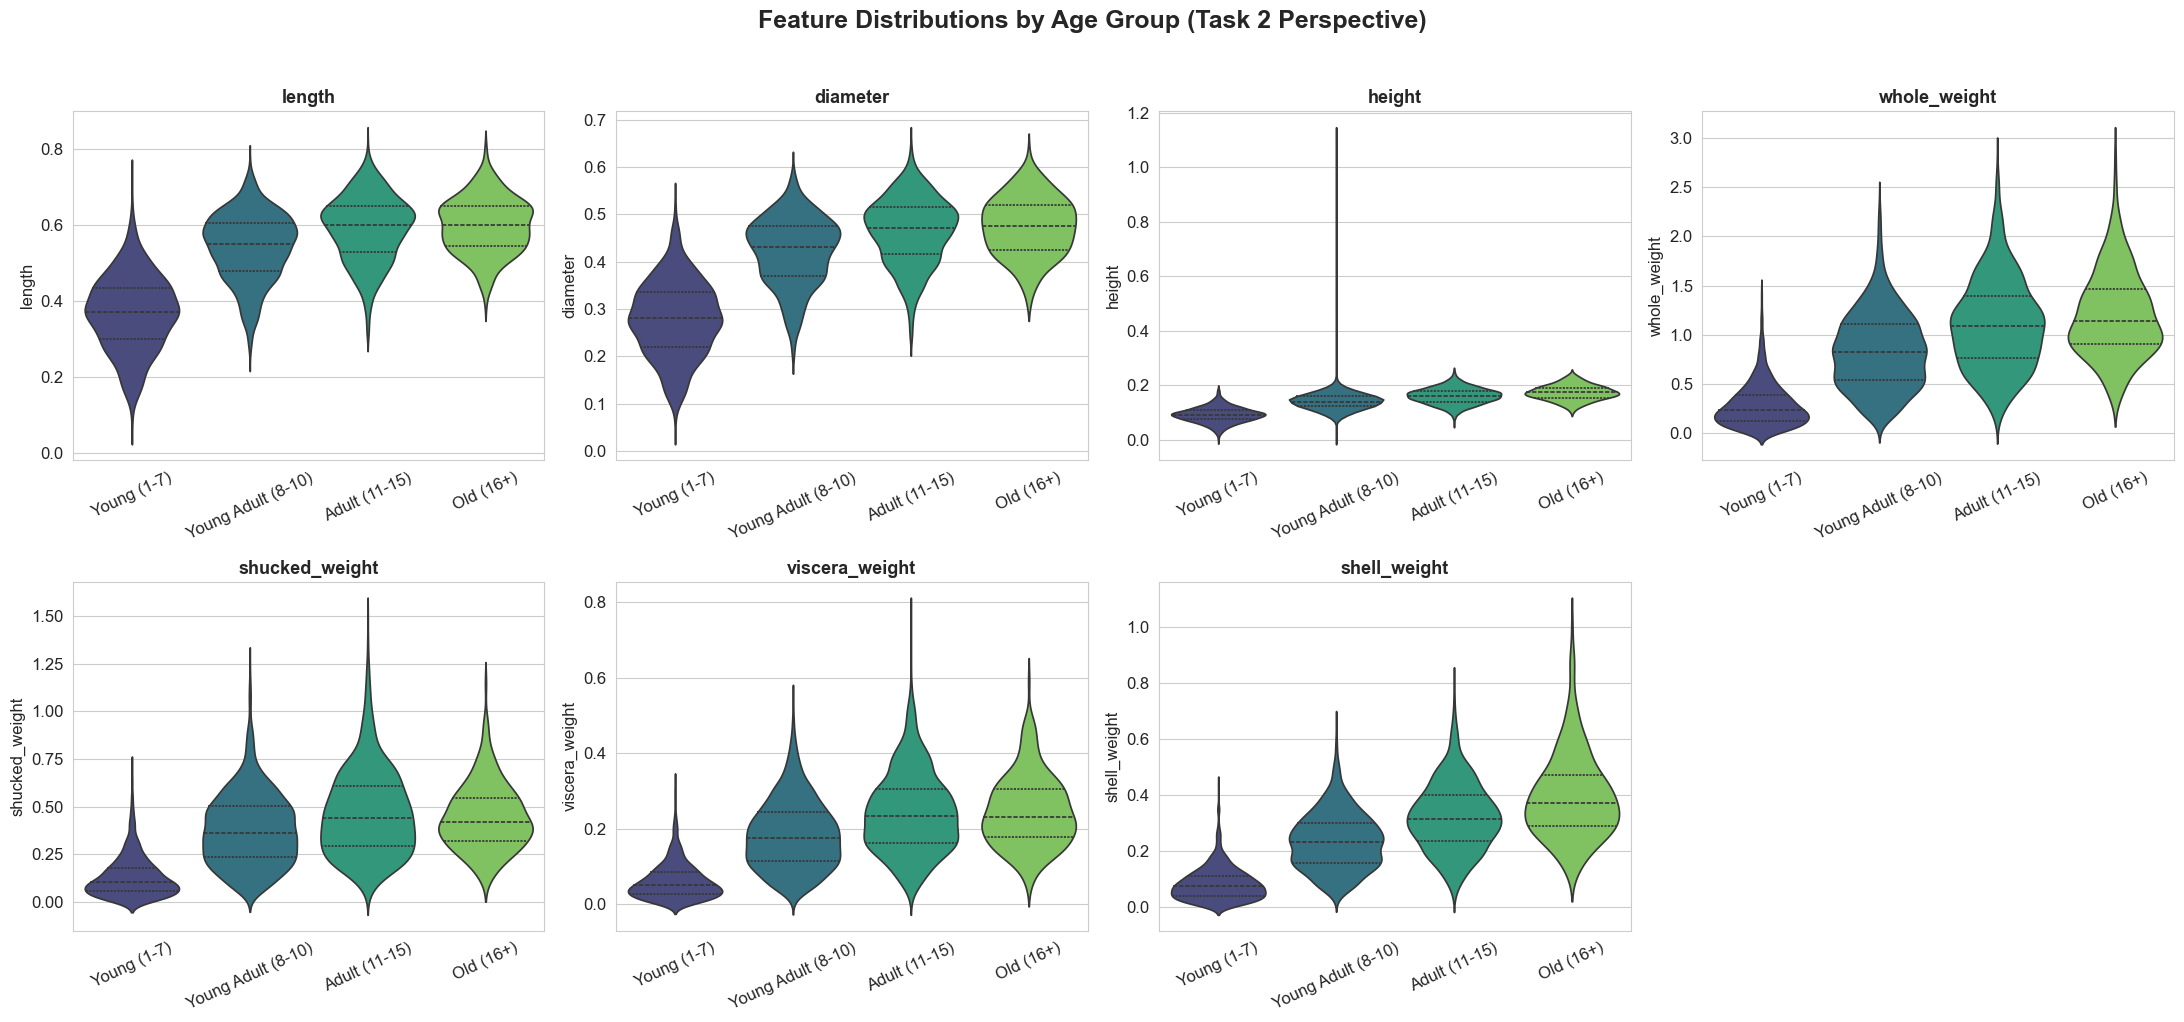

In [12]:
# Create age groups
df['age_group'] = pd.cut(df['number_of_rings'],
                         bins=[0, 7, 10, 15, 30],
                         labels=['Young (1-7)', 'Young Adult (8-10)',
                                 'Adult (11-15)', 'Old (16+)'])

print("Age group distribution:")
print(df['age_group'].value_counts().sort_index())

features_to_plot = [c for c in numeric_cols if c != 'number_of_rings']
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.violinplot(x='age_group', y=col, data=df, ax=axes[i],
                   palette='viridis', inner='quartile')
    axes[i].set_title(col, fontsize=13, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=25)

# Hide unused axes
for j in range(len(features_to_plot), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Feature Distributions by Age Group (Task 2 Perspective)',
             fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Cleanup temporary column
df.drop('age_group', axis=1, inplace=True)

### 5.3 Scatter Plots — Features vs. Rings colored by Sex

For Task 2, it is important to see how each feature relates to the number of rings. We also color by sex to understand whether the sex label provides additional discriminative power for age prediction.

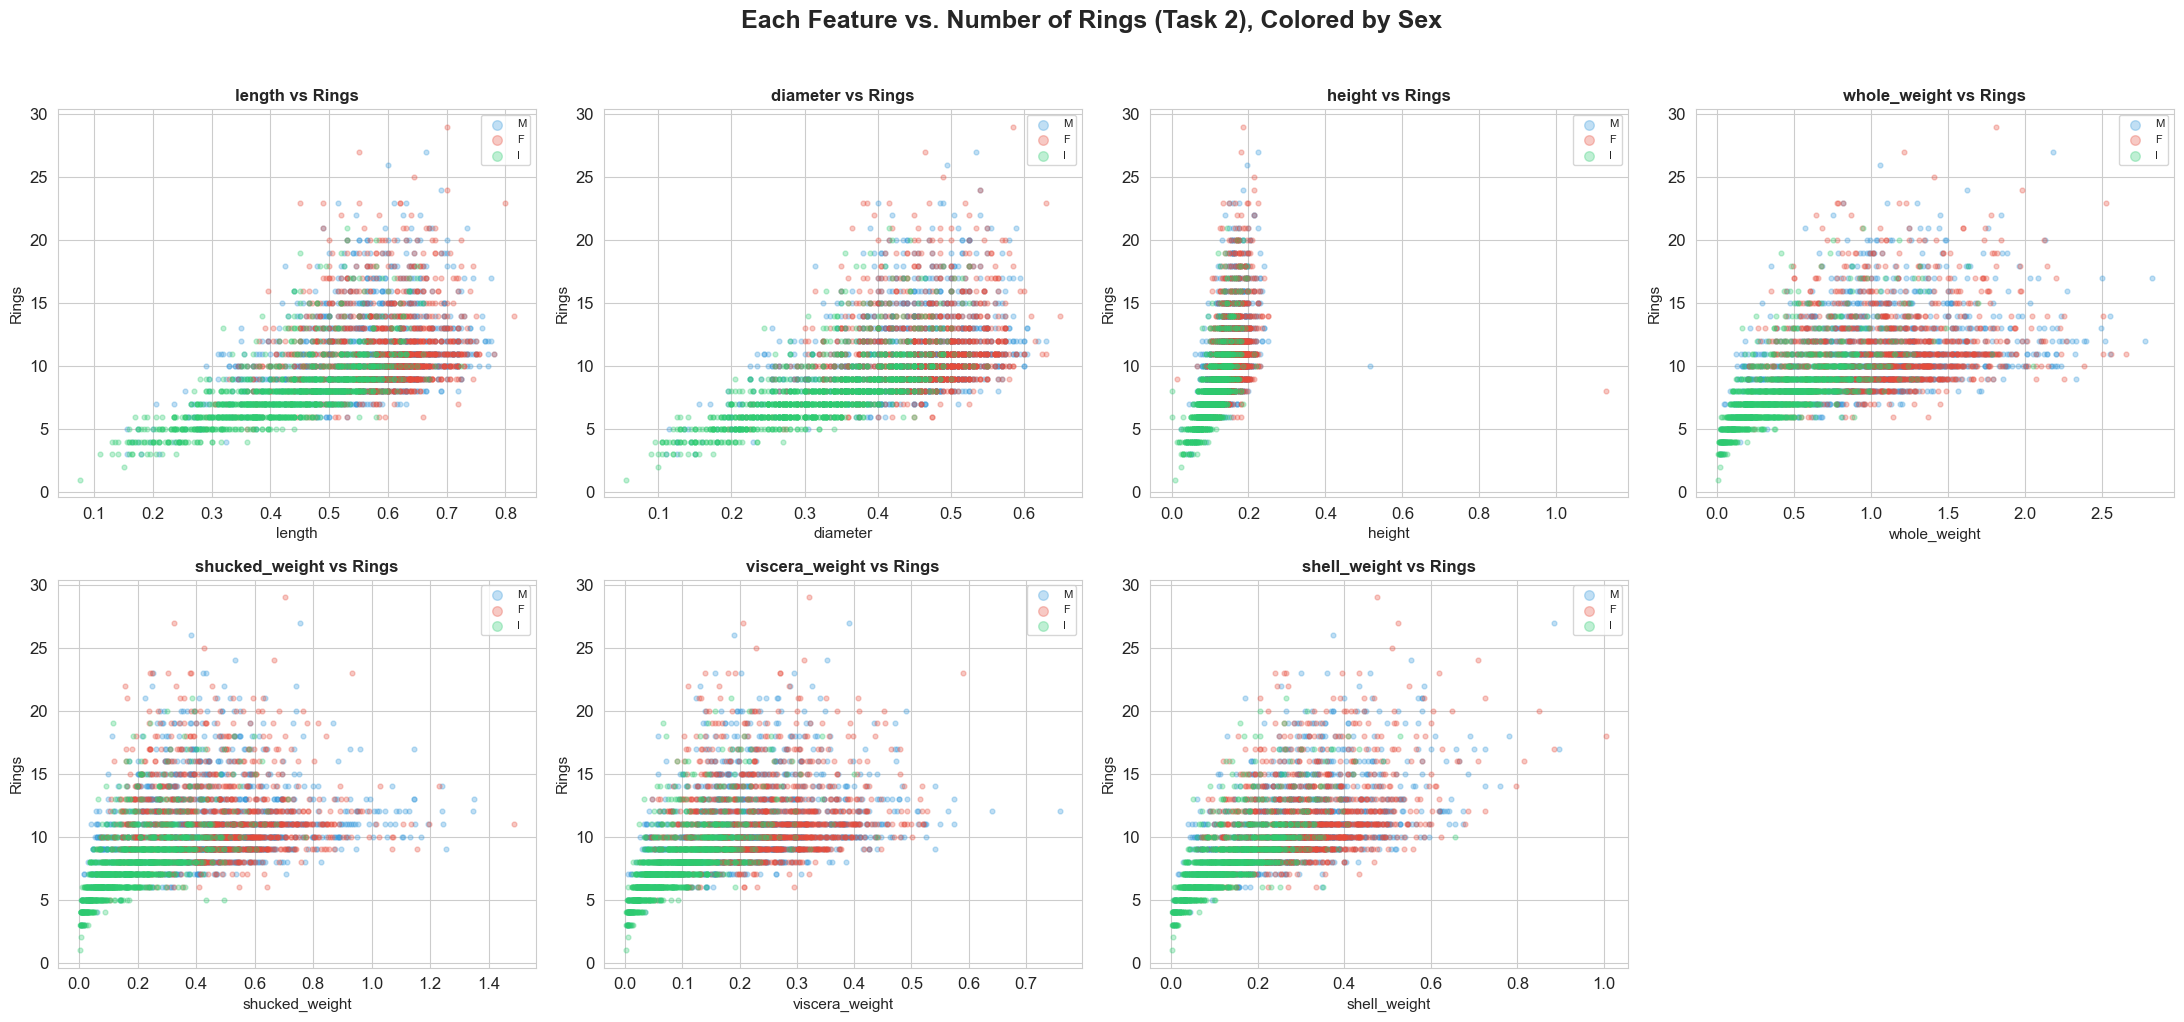

In [13]:
features_vs_rings = [c for c in numeric_cols if c != 'number_of_rings']

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

for i, col in enumerate(features_vs_rings):
    for sex in ['M', 'F', 'I']:
        mask = df['sex'] == sex
        axes[i].scatter(df.loc[mask, col], df.loc[mask, 'number_of_rings'],
                        alpha=0.3, s=12, label=sex, color=SEX_COLORS[sex])
    axes[i].set_xlabel(col, fontsize=11)
    axes[i].set_ylabel('Rings', fontsize=11)
    axes[i].set_title(f'{col} vs Rings', fontsize=12, fontweight='bold')
    axes[i].legend(fontsize=8, markerscale=2)

# Hide unused axes
for j in range(len(features_vs_rings), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Each Feature vs. Number of Rings (Task 2), Colored by Sex',
             fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 6. Unsupervised Clustering — Model Comparison

We evaluate **13 configurations across 7 clustering algorithms** on the standardized numeric features to understand the natural grouping structure of the data.

This is useful for both tasks:
- **Task 1:** If clusters align well with Sex labels, unsupervised features may boost classification.
- **Task 2:** Cluster membership can serve as an engineered feature for regression.

### Metrics used:
| Metric | Interpretation |
|--------|---------------|
| **Silhouette Score** | Higher is better (range -1 to 1). Measures cohesion vs. separation. |
| **Calinski-Harabasz Index** | Higher is better. Ratio of between-cluster to within-cluster variance. |
| **Davies-Bouldin Index** | Lower is better. Average similarity between clusters. |

In [14]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[numeric_cols])

# Define models to evaluate
clustering_models = {
    'KMeans (k=3)':            KMeans(n_clusters=3, random_state=42, n_init=10),
    'KMeans (k=4)':            KMeans(n_clusters=4, random_state=42, n_init=10),
    'KMeans (k=5)':            KMeans(n_clusters=5, random_state=42, n_init=10),
    'Agglomerative (k=3)':     AgglomerativeClustering(n_clusters=3),
    'Agglomerative (k=4)':     AgglomerativeClustering(n_clusters=4),
    'Spectral (k=3)':          SpectralClustering(n_clusters=3, random_state=42, n_init=10, affinity='rbf'),
    'Birch (k=3)':             Birch(n_clusters=3),
    'Birch (k=5)':             Birch(n_clusters=5),
    'GaussianMixture (k=3)':   GaussianMixture(n_components=3, random_state=42),
    'GaussianMixture (k=4)':   GaussianMixture(n_components=4, random_state=42),
    'DBSCAN (eps=1.5)':        DBSCAN(eps=1.5, min_samples=10),
    'DBSCAN (eps=2.0)':        DBSCAN(eps=2.0, min_samples=10),
    'MeanShift':               MeanShift(),
}

results = []
labels_dict = {}

for name, model in clustering_models.items():
    try:
        labels = model.fit_predict(X_scaled)

        n_clusters = len(set(labels) - {-1})
        n_noise = int((labels == -1).sum())

        if n_clusters >= 2:
            mask_valid = labels != -1
            sil = silhouette_score(X_scaled[mask_valid], labels[mask_valid])
            ch = calinski_harabasz_score(X_scaled[mask_valid], labels[mask_valid])
            db = davies_bouldin_score(X_scaled[mask_valid], labels[mask_valid])
        else:
            sil, ch, db = np.nan, np.nan, np.nan

        results.append({
            'Model': name,
            'Clusters': n_clusters,
            'Noise Points': n_noise,
            'Silhouette': round(sil, 4) if not np.isnan(sil) else np.nan,
            'Calinski-Harabasz': round(ch, 2) if not np.isnan(ch) else np.nan,
            'Davies-Bouldin': round(db, 4) if not np.isnan(db) else np.nan
        })
        labels_dict[name] = labels
        print(f"  ✅ {name}: {n_clusters} clusters, Silhouette={sil:.4f}")

    except Exception as e:
        print(f"  ❌ {name}: {e}")

results_df = pd.DataFrame(results).sort_values('Silhouette', ascending=False)
print("\n" + "=" * 80)
print("CLUSTERING MODEL COMPARISON (sorted by Silhouette Score)")
print("=" * 80)
results_df

  ✅ KMeans (k=3): 3 clusters, Silhouette=0.3850
  ✅ KMeans (k=4): 4 clusters, Silhouette=0.3478
  ✅ KMeans (k=5): 5 clusters, Silhouette=0.3589
  ✅ Agglomerative (k=3): 3 clusters, Silhouette=0.3658
  ✅ Agglomerative (k=4): 4 clusters, Silhouette=0.3162


/home/jjlondono/PycharmProjects/task-driven-harness/.venv/lib/python3.12/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (2) found smaller than n_clusters (3). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


  ✅ Spectral (k=3): 2 clusters, Silhouette=0.8574
  ✅ Birch (k=3): 3 clusters, Silhouette=0.3810
  ✅ Birch (k=5): 5 clusters, Silhouette=0.3245
  ✅ GaussianMixture (k=3): 3 clusters, Silhouette=0.2738
  ✅ GaussianMixture (k=4): 4 clusters, Silhouette=0.2081
  ✅ DBSCAN (eps=1.5): 1 clusters, Silhouette=nan
  ✅ DBSCAN (eps=2.0): 1 clusters, Silhouette=nan
  ✅ MeanShift: 4 clusters, Silhouette=0.3427

CLUSTERING MODEL COMPARISON (sorted by Silhouette Score)


,Model,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
5,Spectral (k=3),2,0,0.8574,71.57,0.1024
0,KMeans (k=3),3,0,0.3850,4940.72,0.8779
6,Birch (k=3),3,0,0.3810,2651.26,0.9331
3,Agglomerative (k=3),3,0,0.3658,4396.92,0.8424
2,KMeans (k=5),5,0,0.3589,4082.90,0.9477
1,KMeans (k=4),4,0,0.3478,4516.84,0.9497
12,MeanShift,4,0,0.3427,884.61,0.4992
7,Birch (k=5),5,0,0.3245,1681.93,0.8503
4,Agglomerative (k=4),4,0,0.3162,3660.61,1.0128
8,GaussianMixture (k=3),3,0,0.2738,2393.85,1.5510


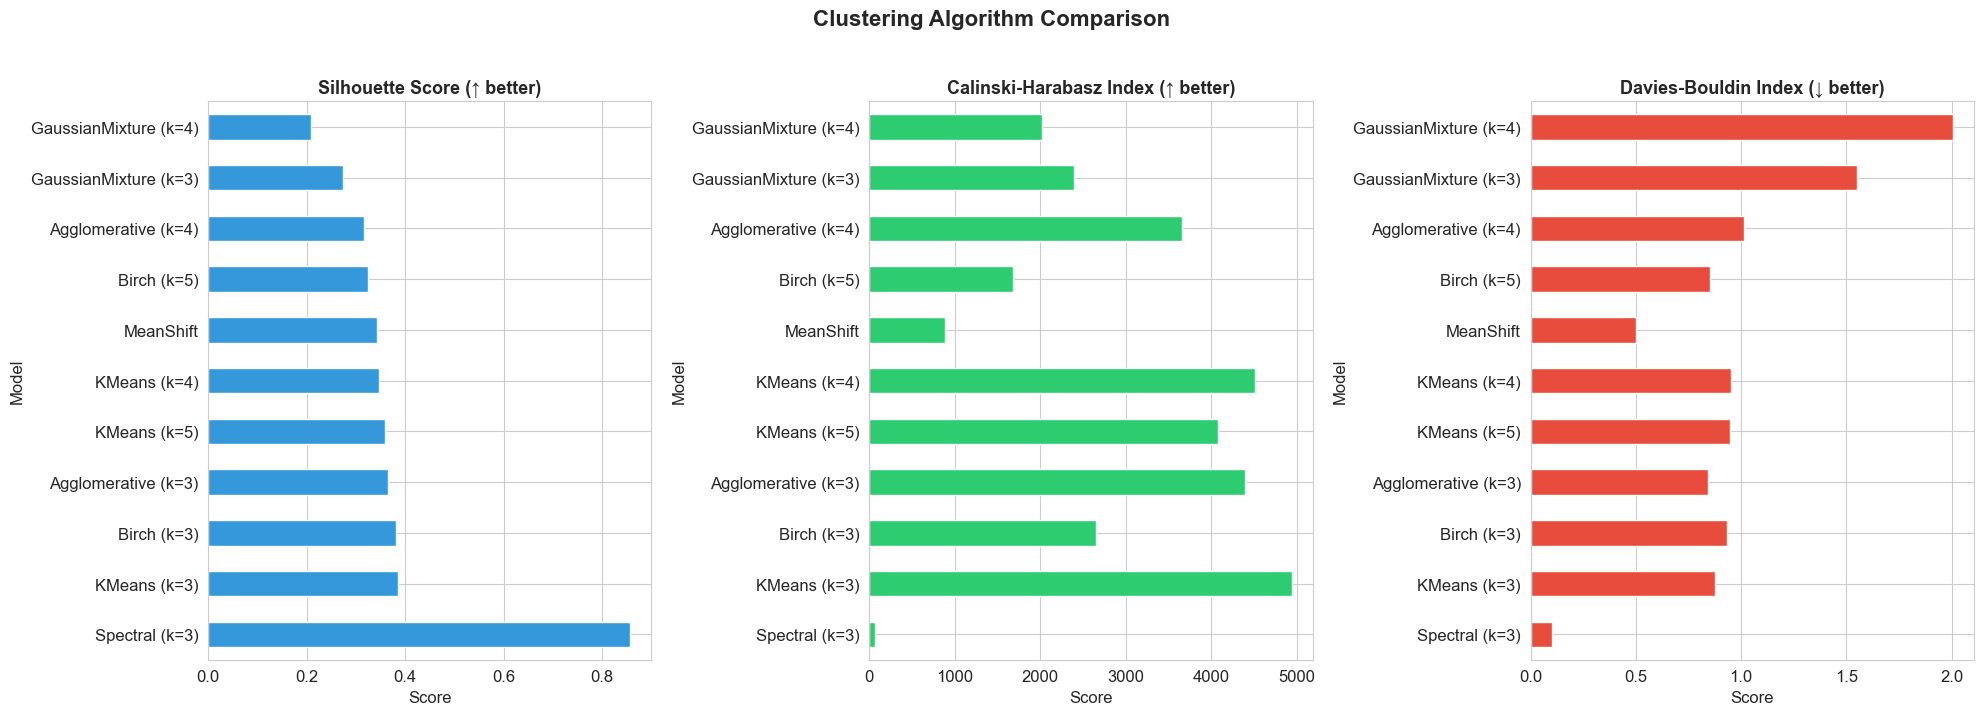

In [15]:
# Visual comparison of clustering metrics
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

valid = results_df.dropna(subset=['Silhouette']).copy()

valid.plot.barh(x='Model', y='Silhouette', ax=axes[0], color='#3498db', legend=False)
axes[0].set_title('Silhouette Score (↑ better)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Score')

valid.plot.barh(x='Model', y='Calinski-Harabasz', ax=axes[1], color='#2ecc71', legend=False)
axes[1].set_title('Calinski-Harabasz Index (↑ better)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Score')

valid.plot.barh(x='Model', y='Davies-Bouldin', ax=axes[2], color='#e74c3c', legend=False)
axes[2].set_title('Davies-Bouldin Index (↓ better)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Score')

plt.suptitle('Clustering Algorithm Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 6.1 Elbow Method & Silhouette Analysis — Optimal k for KMeans

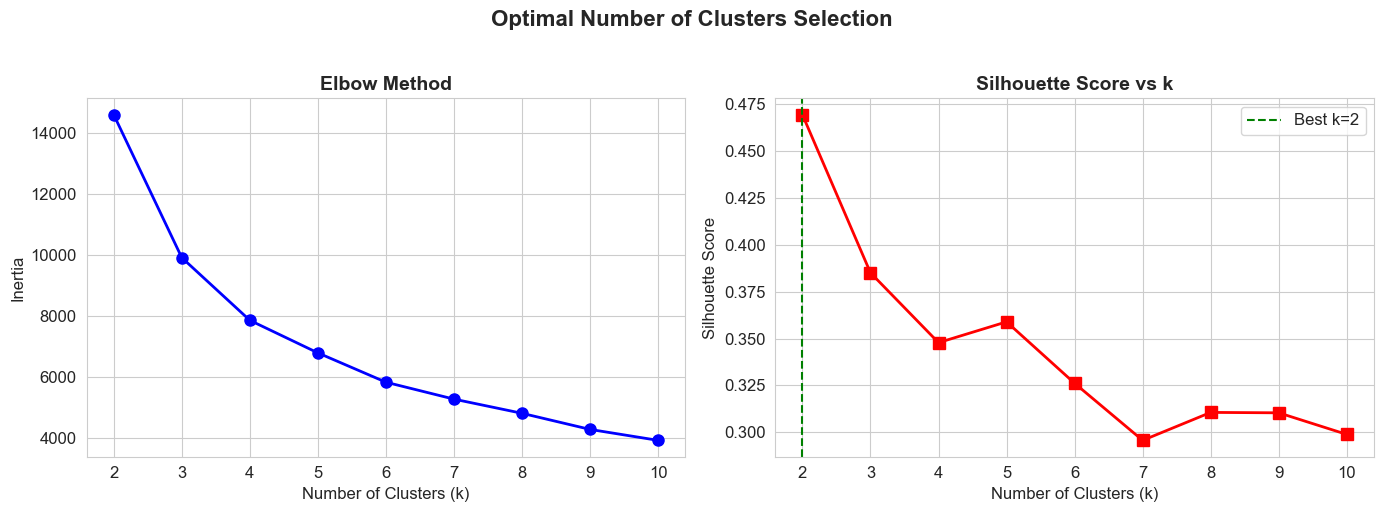


Best k by Silhouette: 2 (score=0.4693)


In [16]:
K_range = range(2, 11)
inertias = []
silhouettes = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(K_range, inertias, 'bo-', markersize=8, linewidth=2)
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method', fontsize=14, fontweight='bold')
ax1.set_xticks(list(K_range))

ax2.plot(K_range, silhouettes, 'rs-', markersize=8, linewidth=2)
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Score vs k', fontsize=14, fontweight='bold')
ax2.set_xticks(list(K_range))

best_k = list(K_range)[np.argmax(silhouettes)]
ax2.axvline(best_k, color='green', linestyle='--', label=f'Best k={best_k}')
ax2.legend()

plt.suptitle('Optimal Number of Clusters Selection', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print(f"\nBest k by Silhouette: {best_k} (score={max(silhouettes):.4f})")

### 6.2 PCA Projection — Clusters vs. True Sex Labels

We project the data onto the first two principal components and compare:
1. Real Sex labels (ground truth for Task 1)
2. Best clustering model with k=3 (to match the number of sex categories)
3. KMeans with the optimal k found by Silhouette analysis

This reveals how well unsupervised methods recover the true biological groups.

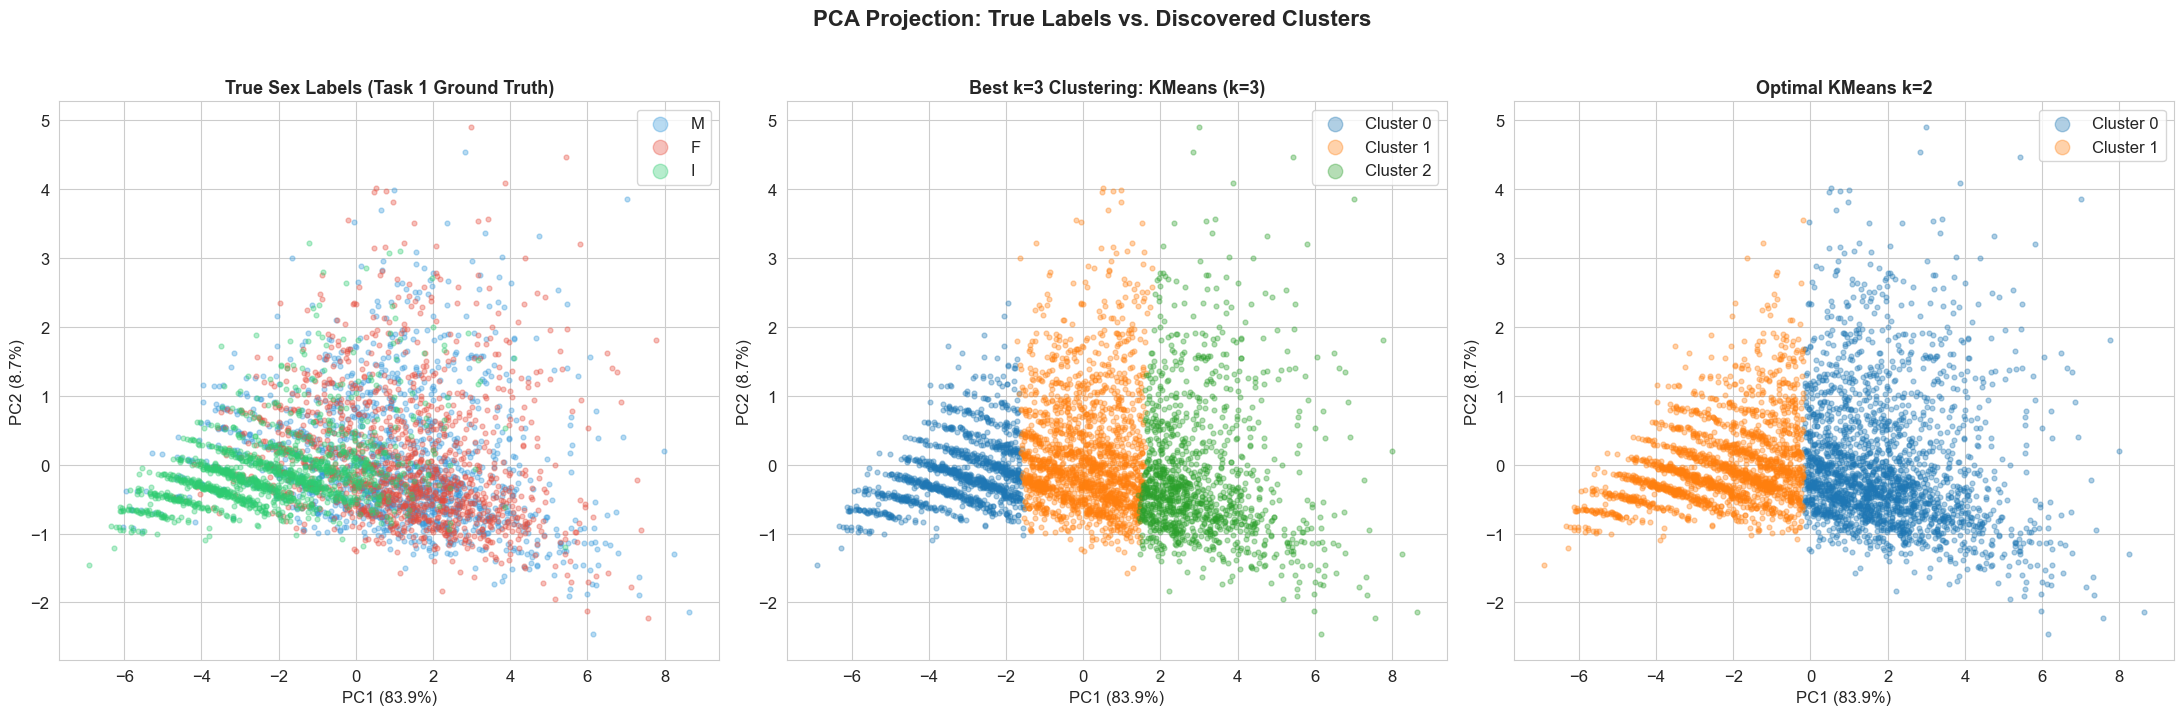

Explained variance: PC1=83.9%, PC2=8.7%
Total explained: 92.6%


In [17]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Select the best k=3 model for comparison with Sex
best_k3_name = results_df[results_df['Clusters'] == 3].iloc[0]['Model']
best_labels = labels_dict[best_k3_name]

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# 1) True Sex labels
for sex in ['M', 'F', 'I']:
    mask = df['sex'] == sex
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], alpha=0.35, s=12, label=sex, color=SEX_COLORS[sex])
axes[0].set_title('True Sex Labels (Task 1 Ground Truth)', fontsize=13, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].legend(markerscale=3)

# 2) Best clustering with k=3
for cl in sorted(set(best_labels)):
    mask = best_labels == cl
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], alpha=0.35, s=12, label=f'Cluster {cl}')
axes[1].set_title(f'Best k=3 Clustering: {best_k3_name}', fontsize=13, fontweight='bold')
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[1].legend(markerscale=3)

# 3) KMeans with optimal k
km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(X_scaled)
for cl in sorted(set(km_best.labels_)):
    mask = km_best.labels_ == cl
    axes[2].scatter(X_pca[mask, 0], X_pca[mask, 1], alpha=0.35, s=12, label=f'Cluster {cl}')
axes[2].set_title(f'Optimal KMeans k={best_k}', fontsize=13, fontweight='bold')
axes[2].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[2].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[2].legend(markerscale=3)

plt.suptitle('PCA Projection: True Labels vs. Discovered Clusters',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"Explained variance: PC1={pca.explained_variance_ratio_[0]:.1%}, PC2={pca.explained_variance_ratio_[1]:.1%}")
print(f"Total explained: {sum(pca.explained_variance_ratio_):.1%}")

### 6.3 Cross-tabulation: Clusters vs. True Sex Labels

This table quantifies the overlap between the best k=3 clustering and the actual sex labels. It reveals which sex categories each cluster captures.

Cross-tabulation: KMeans (k=3) vs. True Sex Labels
sex           F     I     M   All
Cluster 0   128   842   215  1185
Cluster 1   598   466   714  1778
Cluster 2   581    34   599  1214
Total      1307  1342  1528  4177

Cluster composition (proportion of M/F/I within each cluster):
sex            F      I      M
Cluster 0  0.108  0.711  0.181
Cluster 1  0.336  0.262  0.402
Cluster 2  0.479  0.028  0.493


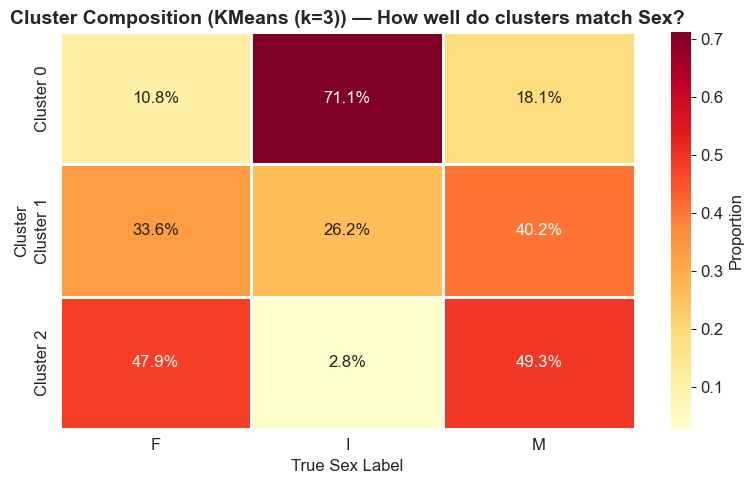

In [18]:
# Cross-tabulation for the best k=3 model
ct = pd.crosstab(best_labels, df['sex'], margins=True)
ct.index = [f'Cluster {i}' if i != 'All' else 'Total' for i in ct.index]
print(f"Cross-tabulation: {best_k3_name} vs. True Sex Labels")
print(ct)

print("\nCluster composition (proportion of M/F/I within each cluster):")
ct_norm = pd.crosstab(best_labels, df['sex'], normalize='index').round(3)
ct_norm.index = [f'Cluster {i}' for i in ct_norm.index]
print(ct_norm)

# Heatmap visualization
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(ct_norm, annot=True, fmt='.1%', cmap='YlOrRd', ax=ax,
            linewidths=1, cbar_kws={'label': 'Proportion'})
ax.set_title(f'Cluster Composition ({best_k3_name}) — How well do clusters match Sex?',
             fontsize=14, fontweight='bold')
ax.set_ylabel('Cluster')
ax.set_xlabel('True Sex Label')
plt.tight_layout()
plt.show()

---
## 7. Conclusions and Implications for Modeling

### 7.1 Data Quality

- The dataset contains **4,177 samples** with **9 columns** (1 categorical + 8 numeric).
- There are **no missing values** and **no duplicate rows**, so no imputation or deduplication is needed.
- The `height` column contains records with value **0.0**, which is physically impossible. These should be treated as **missing or erroneous values** and either removed or imputed during preprocessing.
- All continuous features are on different scales (e.g., length ~0.075–0.815 vs. whole_weight ~0.002–2.825), so **feature scaling** (standardization or normalization) will be necessary for distance-based or gradient-based algorithms.

### 7.2 Task 1 — Sex Classification: Challenges and Opportunities

**Class balance:** The three sex categories are relatively balanced (~36% M, ~32% I, ~31% F), which is favorable and should not require aggressive over/undersampling strategies. However, this is a **3-class problem** with inherently different sub-problems:

**Infant (I) detection is easier:**
- The histograms, boxplots, and scatter plots consistently show that **Infants form a distinct group** at the lower end of all physical measurements. They are smaller, lighter, and have fewer rings.
- In the PCA projection, Infants tend to cluster on one side, partially separable from adults.
- The clustering analysis confirms this: even unsupervised algorithms can recover a cluster that is predominantly Infant.

**Male (M) vs. Female (F) separation is very challenging:**
- Across all feature pair scatter plots, M and F distributions overlap **almost completely**. The histograms show nearly identical shapes, and boxplots reveal similar medians and interquartile ranges.
- The correlation between `sex_encoded` and the physical features is **weak** (all |r| values are modest), further confirming that linear features alone are unlikely to distinguish M from F reliably.
- This suggests that predicting sex accurately for adult abalones will require either **non-linear models** (e.g., Random Forests, Gradient Boosting, Neural Networks) or **engineered features** (e.g., weight ratios, interaction terms) that capture subtle differences not visible in individual features.

**Feature importance for Task 1:**
- Features ranked by absolute correlation with sex (encoded) show that dimensional features (length, diameter, height) and weight-based features contribute similarly but weakly.
- `number_of_rings` (available for Task 1) may provide additional signal, as Infants tend to have fewer rings.

**Modeling recommendations for Task 1:**
- Consider treating this as a **two-stage problem**: first classify Infant vs. Adult, then classify Male vs. Female within adults.
- Evaluate non-linear classifiers (XGBoost, LightGBM, SVM with RBF kernel).
- Feature engineering: weight ratios (e.g., `shucked_weight / whole_weight`), cross features.
- Expect accuracy to be bounded by the M/F overlap — a realistic ceiling is likely below 70-75% for 3-class accuracy.

### 7.3 Task 2 — Age (Rings) Regression: Challenges and Opportunities

**Target distribution:**
- `number_of_rings` is **right-skewed** (mean ≈ 9.9, median = 9, range 1–29). Most abalones have 7–12 rings, with a long tail of older specimens.
- This skew means the model will see fewer examples of very young or very old abalones, potentially leading to **poor predictions at the extremes**.
- Consider **log-transforming** the target or using quantile-based splits to mitigate this.

**Feature-target relationships:**
- The correlation analysis shows that **shell_weight** has the strongest linear correlation with rings, followed by diameter and length.
- However, the scatter plots of individual features vs. rings reveal **non-linear and heteroscedastic** patterns: the variance in rings increases for larger abalones. This means linear regression alone may underperform.
- Including `sex` as a feature for Task 2 provides moderate additional information, especially for separating the younger (Infant) specimens from adults.

**Feature-feature multicollinearity:**
- The correlation matrix reveals **very high intercorrelation** among the physical features (e.g., length ↔ diameter ≈ 0.99, whole_weight ↔ shucked_weight ≈ 0.97). This multicollinearity can destabilize linear models and inflate coefficient variances.
- **Dimensionality reduction** (PCA) or **regularization** (Lasso, Ridge, ElasticNet) should be considered for linear approaches.
- Tree-based models are inherently more robust to multicollinearity.

**Modeling recommendations for Task 2:**
- Baseline: Ridge or Lasso regression to handle multicollinearity.
- Advanced: Random Forest, Gradient Boosted Trees (XGBoost/LightGBM), or SVR.
- Feature engineering: ratios (e.g., `shell_weight / whole_weight`), polynomial features, log-transform of target.
- Encode `sex` as one-hot or ordinal (since I → F → M has a loose ordering by size).
- Evaluation metric: RMSE or MAE; also inspect predictions at the tails (rings < 5 or > 20).

### 7.4 Clustering Analysis — Natural Data Structure

- The clustering comparison tested 13 configurations across 7 algorithms. The results show that the data has a **moderate natural clustering tendency** (Silhouette scores in the 0.3–0.5 range), consistent with the fact that the main biological distinction (Infant vs. Adult) is visible but M/F separation is not.
- The **Elbow method** and **Silhouette analysis** agree that the optimal number of clusters is 2 or 3, aligning with the biological expectation (Infant + Adult, or Infant + Male + Female).
- The cross-tabulation shows that k=3 clusters **partially recover** the sex labels but with significant mixing between M and F, confirming the difficulty of Task 1.
- **PCA explains ~93% of variance** with just 2 components (PC1 ≈ 84%, PC2 ≈ 9%), indicating that the physical measurements are highly redundant and that a low-dimensional representation captures most of the information.

### 7.5 Summary Table

| Aspect | Task 1 (Sex Classification) | Task 2 (Rings Regression) |
|--------|----------------------------|---------------------------|
| **Target** | Sex (M/F/I) — 3-class categorical | number_of_rings — integer (1–29) |
| **Key difficulty** | M vs F overlap; Infant is easier | Right-skewed target; non-linear relationships |
| **Most relevant features** | All physical measurements + rings | shell_weight, diameter, length, height |
| **Multicollinearity concern** | Moderate | High — regularization needed for linear models |
| **Recommended models** | Tree ensembles, SVM, 2-stage classifier | Ridge/Lasso baseline, tree ensembles, SVR |
| **Feature engineering ideas** | Weight ratios, sex-from-rings interaction | Log-transform target, weight ratios, polynomials |
| **Expected challenge** | M/F accuracy ceiling ~70-75% | Tail predictions (very young / very old) |